# EDA Criteo

Смотрим состав данных, качество и ограничения для прогноза конверсии и выбора ставок.
Анализ выполнен на полном архиве [Criteo Attribution Modeling for Bidding](https://huggingface.co/datasets/criteo/criteo-attribution-dataset).
Данные и локальная БД не включены в Git. Агрегаты рассчитывает `scripts/run_eda.py`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "reports/eda").exists():
    ROOT = ROOT.parent
REPORT = ROOT / "reports/eda"
manifest = json.loads((REPORT / "manifest.json").read_text())
display(manifest)
display(pd.read_csv(REPORT / "tables/summary.csv"))

{'file': 'criteo_attribution_dataset.tsv.gz',
 'bytes': 653015824,
 'sha256': '94ac7a465564349bc7ba008602211d5990a3c53cc133abc0aadef61ea2391a98',
 'rows': 16468027,
 'split_boundaries_seconds': [1602720, 2136960],
 'memory_limit': '1GB',
 'threads': 2,
 'duckdb_version': '2.0.0',
 'plot_sample_rows': 100000,
 'seed': 42,
 'source_revision': '904188a63cbad78bee43cd26ff5ee4ac77903986',
 'url': 'https://huggingface.co/datasets/criteo/criteo-attribution-dataset/resolve/904188a63cbad78bee43cd26ff5ee4ac77903986/criteo_attribution_dataset.tsv.gz'}

,rows,users,campaigns,min_timestamp,max_timestamp,positive_rows,positive_rate,clicks,attributed_rows,conversions,raw_conversion_ids,total_cost
0,16468027,6142256,675,0,2671199,806196.0,0.048955,5947563.0,442424.0,438730,435810,4829.340541


## 1. Состав данных

16 468 027 показов, 6 142 256 пользователей, 675 кампаний и 22 поля.
Период — 30 дней 22 часа. Строка — состоявшийся показ с контекстом, стоимостью
и последующими кликами и конверсией. Поля `cat1`–`cat9` обезличены.
Все таблицы рассчитаны по полному набору. Исключение — график стоимости,
для которого взяты 100 000 строк с фиксированным правилом отбора.

## 2. Качество данных

NULL, полных дубликатов и некорректных меток или стоимостей в проверках не найдено.
Но у `time_since_last_click` в 8 770 820 строках (53,26%) стоит `-1`.
Это отсутствие истории, его нужно обрабатывать отдельно.

Конверсии, клики текущего показа и его фактическую стоимость нельзя использовать
как признаки для решения о ставке: они становятся известны позже.

## 3. Конверсии

Положительных строк — 806 196 (4,90%), а уникальных составных событий — 438 730.
Одна конверсия может быть связана с несколькими показами.
Кроме того, у 2 910 значений `conversion_id` различаются пользователь и время.
Поэтому считаем событие по `(uid, conversion_id, conversion_timestamp)`.

На графике ниже события отнесены к дню показа. Их нельзя просто суммировать
между днями: итог за весь период требует повторной дедупликации.

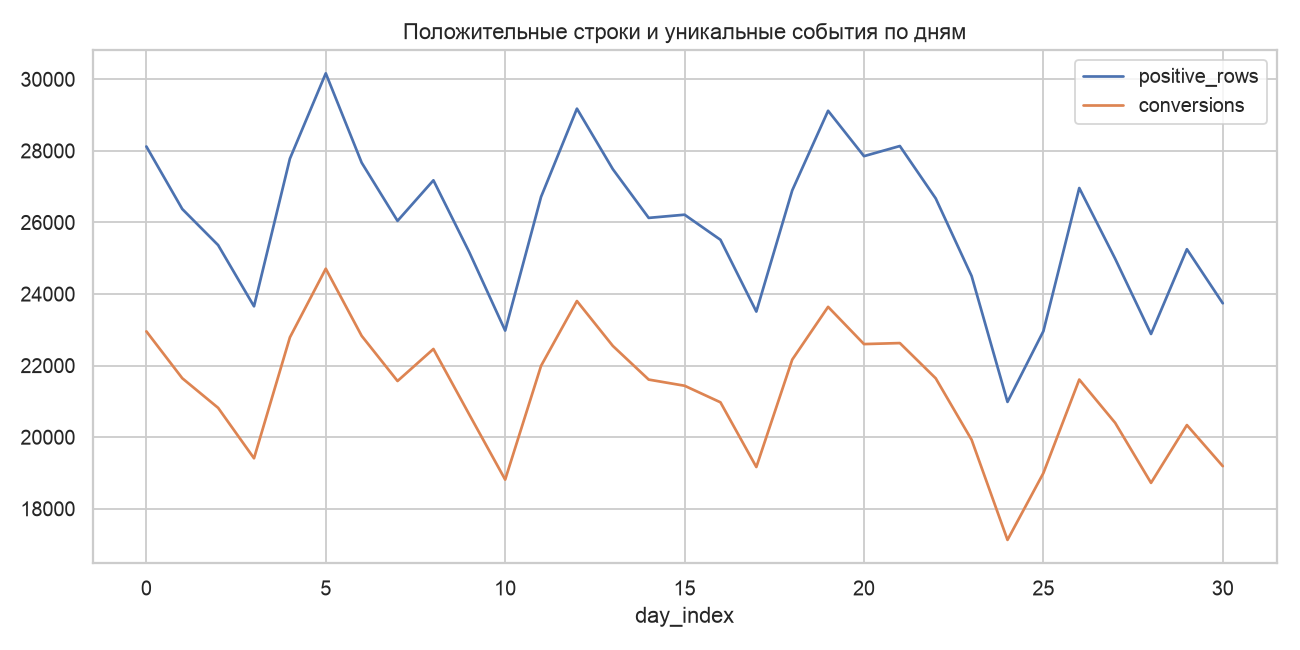

In [2]:
display(Image(filename=str(REPORT / "figures/daily_outcomes.png")))

## 4. Трафик по времени

Суточный трафик меняется от 436 до 638 тысяч показов. Последний день неполный.
Поэтому используем временное разделение выборок и сравниваем стратегии на
одинаковых днях. Дневные расходы также сохранены в `tables/daily.csv`.

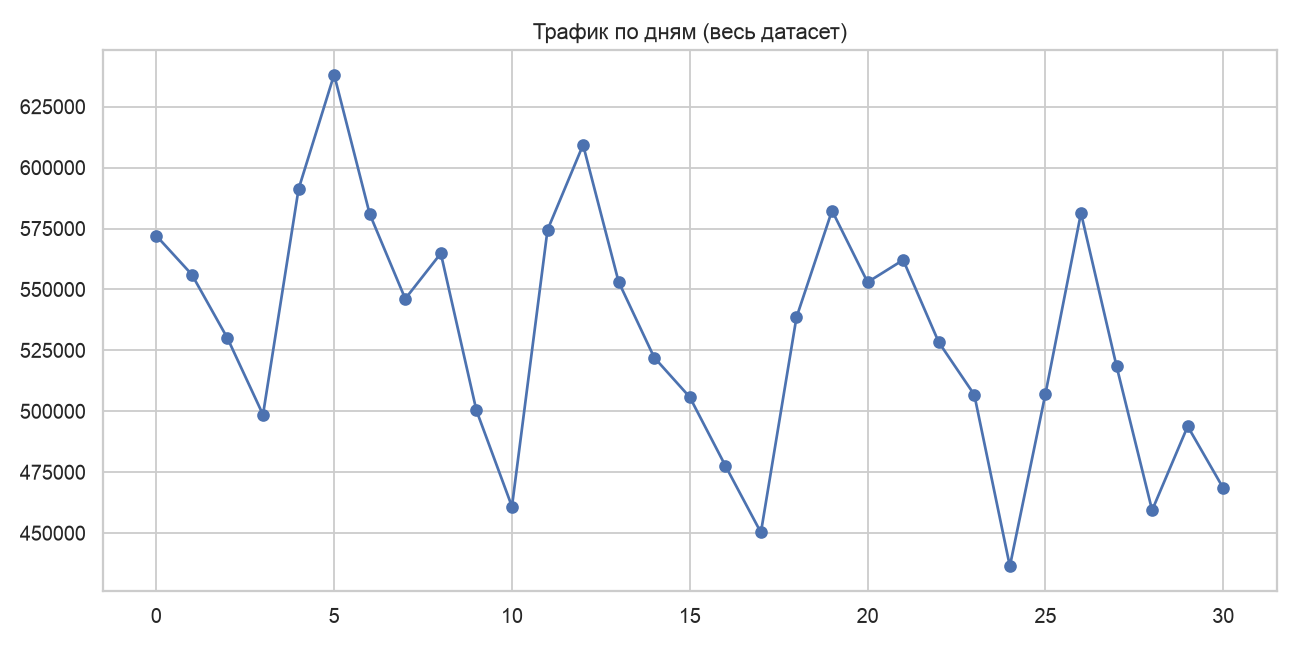

In [3]:
display(Image(filename=str(REPORT / "figures/daily.png")))

## 5. Различия между кампаниями

На десять крупнейших по числу событий кампаний приходится 30,40% конверсий.
У 279 кампаний меньше 100 событий, у четырёх — меньше 10.
Общая модель pConv позволит использовать данные всех кампаний, а для UCB
нужно учитывать, что малые кампании медленно накапливают обратную связь.

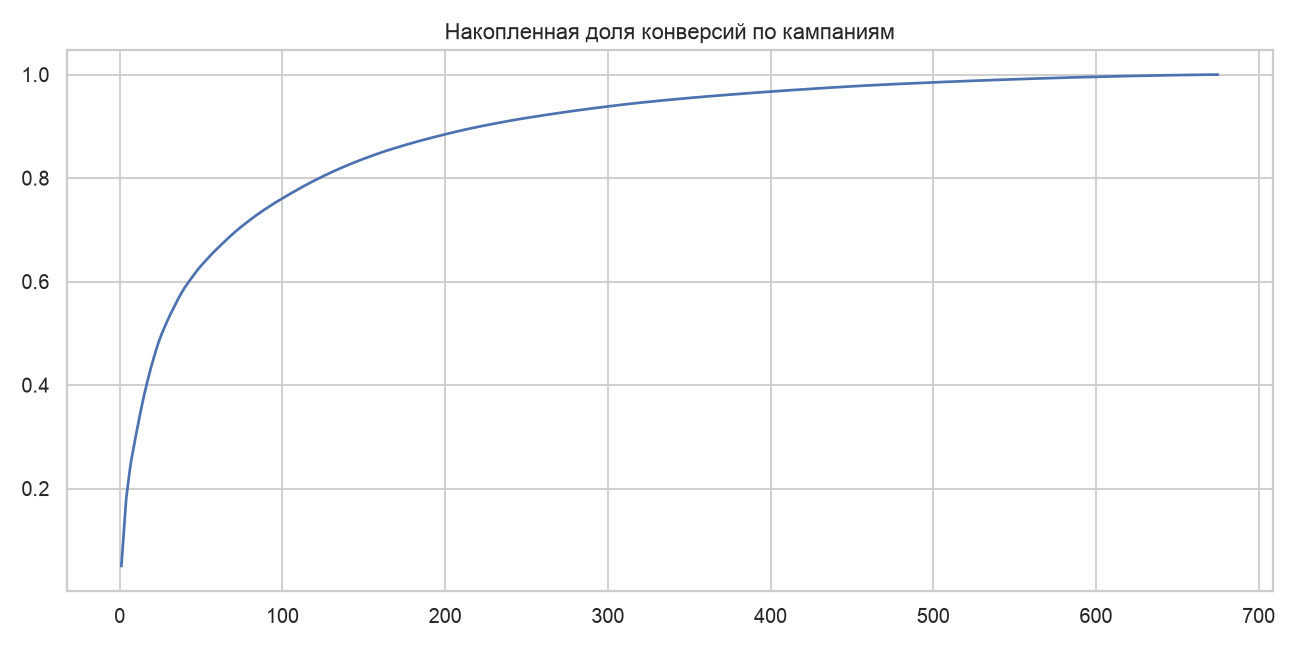

In [4]:
display(Image(filename=str(REPORT / "figures/concentration.png")))

## 6. Задержка конверсии

Медиана задержки положительной строки — 3,74 дня, p95 — 25,13 дня.
У 182 792 положительных строк событие происходит после окончания потока показов.
Только 3,31% показов имеют полный 30-дневный интервал до конца этого потока.
Это не подтверждает полноту сбора отрицательных исходов.

UCB не должен получать готовые метки сразу. Нужна очередь ожидающих результатов
и более длинный поток для проверки адаптации. График взвешен по положительным
строкам, а не по независимым покупкам.

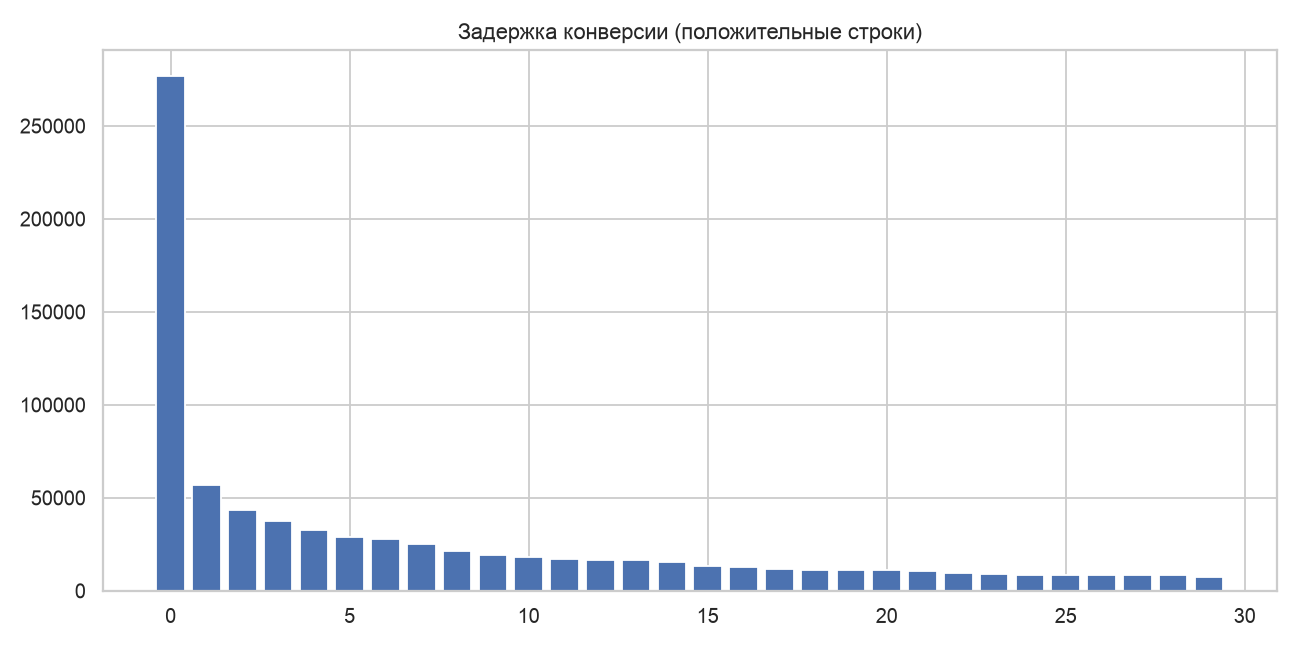

In [5]:
display(Image(filename=str(REPORT / "figures/delay.png")))

## 7. Категориальные признаки

Больше всего категорий у `cat7` — 57 196. В test появляются неизвестные train
категории: 1,30% строк для `cat3` и 0,78% для `cat7`.
Нужны разреженное кодирование и обработка новых значений.
Числовые коды категорий не имеют количественного смысла.

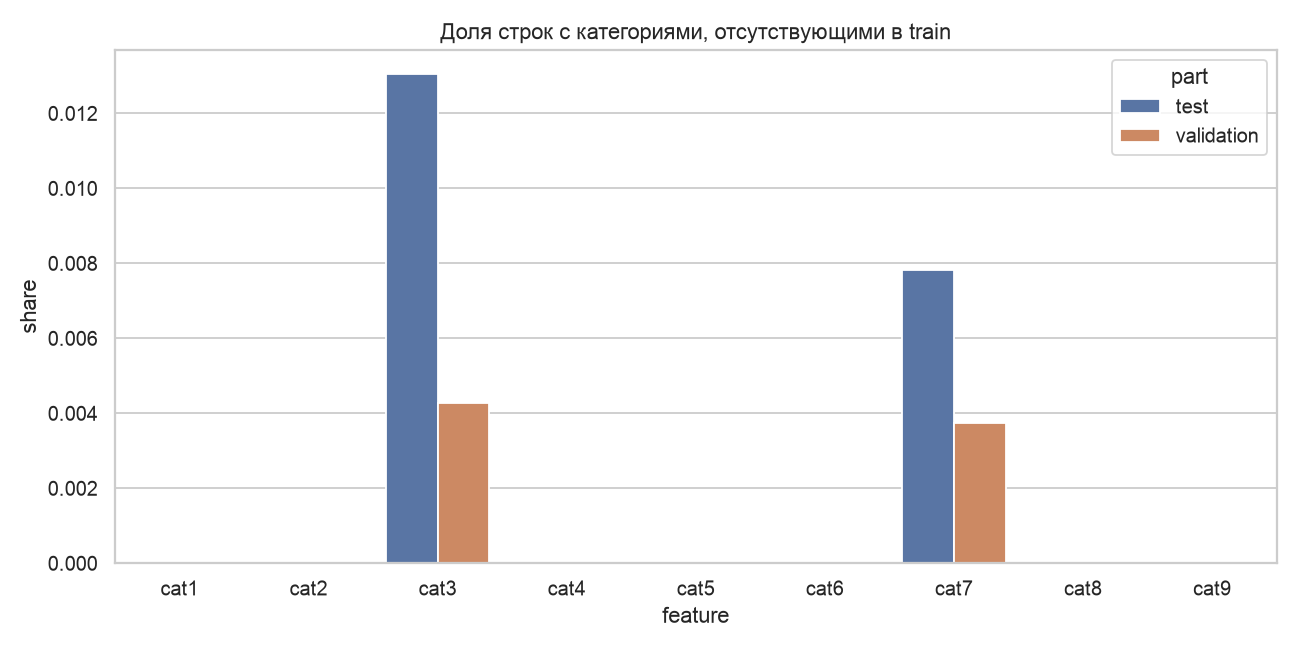

In [6]:
display(Image(filename=str(REPORT / "figures/unseen.png")))

## 8. Стоимости

Медиана `cost` — 0,00007610, p99 — 0,00345560: распределение имеет длинный хвост.
Гистограмма построена по фиксированной выборке 100 000 строк, ось частот логарифмическая.

Цены преобразованы, поэтому бюджет и CPA измеряем в условных единицах.
Проигранных аукционов нет: симулятор с правилом `bid >= cost` даст только
приближённое сравнение.

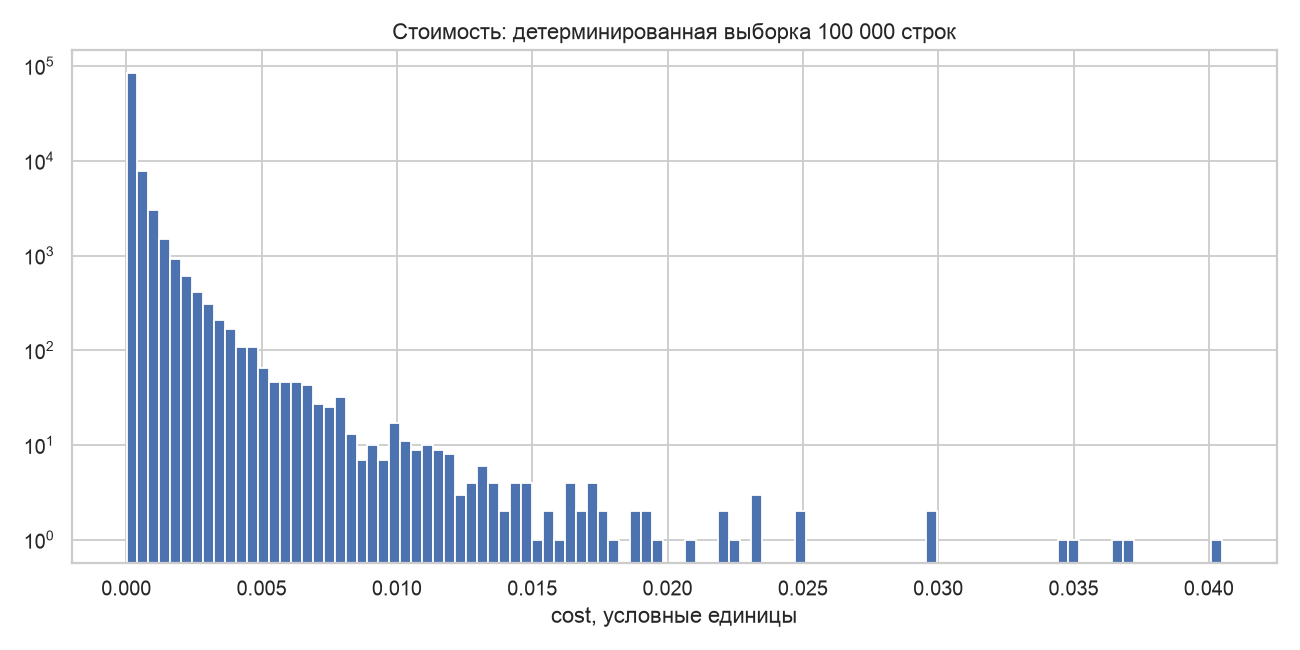

In [7]:
display(Image(filename=str(REPORT / "figures/cost.png")))

## 9. Валидация и дальнейшие шаги

Делим поток по времени в отношении 60/20/20. Между train и test пересекаются
894 475 пользователей и 13 671 составное событие конверсии.
Такое разделение подходит для ретроспективного исследования, но не воспроизводит
обучение с полным 30-дневным ожиданием меток.

Сначала сравним постоянную вероятность и логистическую регрессию. Затем —
фиксированную ставку и семейство UCB. Модели и стратегии пока не обучались.

In [8]:
display(pd.read_csv(REPORT / "tables/splits.csv"))
display(pd.read_csv(REPORT / "tables/field_quality.csv"))
display(pd.read_csv(REPORT / "tables/event_key_audit.csv"))

,part,impressions,positive_rows,positive_rate,users,campaigns,conversions,start,finish
0,train,9941432,486325.0,0.048919,4360220,675,281954,0,1602719
1,validation,3344259,166178.0,0.049691,2001520,672,108678,1602720,2136959
2,test,3182336,153693.0,0.048296,1926832,669,100986,2136960,2671199


,field,nulls,minus_one,zeros,cardinality
0,timestamp,0,0,1,2455294
1,uid,0,0,0,6142256
2,campaign,0,0,0,675
3,conversion,0,0,15661831,2
4,conversion_timestamp,0,15661831,0,407345
5,conversion_id,0,15661831,0,435811
6,attribution,0,0,16025603,2
7,click,0,0,10520464,2
8,click_pos,0,15661831,400152,175
9,click_nb,0,15661831,0,107


,events,multi_campaign_events,inconsistent_times
0,438730,0,0


## Повторный запуск

Из корня проекта:

```bash
uv sync --locked --group eda
uv run --group eda python scripts/download_data.py
uv run --group eda python scripts/run_eda.py
uv run --group eda jupyter lab notebooks/01_criteo_eda.ipynb
```

Проверки подготовки данных: `uv run --group eda python -m unittest discover -s tests`.
Источник и SHA-256 сохранены в `reports/eda/manifest.json`.
Лицензия данных — CC BY-NC-SA 4.0; авторы: Eustache Diemert, Julien Meynet,
Pierre Galland, Damien Lefortier, [статья](https://arxiv.org/abs/1707.06409).